# Active Learning for Mushroom Edibility Classification

**Milestone 2 — Refactored Pipeline**

Key design decisions vs. Milestone 1:

- **Encoding**: `OneHotEncoder` for categoricals (not `LabelEncoder`). Ordinal integer encoding of unordered categories injects a spurious numeric order (e.g. `brown=0 < red=1 < white=2`) that distorts both linear models and distance-based methods.
- **Evaluation**: a fixed held-out test set is carved out up front; every AL round evaluates against it. CV-on-the-labeled-set (previous approach) is biased because the labeled set is selection-biased by the query strategy.
- **Fair baselines**: both random and D-optimal initialization are class-stratified. Previously only random was stratified, so any gap was confounded with class balance.
- **Metrics**: accuracy, balanced accuracy, poisonous recall, poisonous F1. Poisonous recall is the safety-critical metric for this application.
- **Explicit stopping**: `stop_reason` flag replaces the confusing `while ... else` construct.


In [1]:
# ==================== IMPORTS ====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# Preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load Data

The secondary mushroom dataset (~61k samples) uses semicolon-delimited plain categorical values.

In [2]:
pool_data = pd.read_csv('data/MushroomDataset/secondary_data.csv', sep=';')
print(f"Dataset shape: {pool_data.shape}")
print(f"Class distribution:\n{pool_data['class'].value_counts()}")

Dataset shape: (61069, 21)
Class distribution:
class
p    33888
e    27181
Name: count, dtype: int64


## 1.5 Exploratory Data Analysis

Inspect the raw data before committing to preprocessing / modeling choices:

1. **Missingness** — rate per column, and whether missingness itself is predictive of the class.
2. **Categorical cardinality and signal** — informs one-hot dimensionality and per-feature predictive power.
3. **Numeric distributions** — skew, outliers, class-conditional separation.

In [4]:
# ==================== EDA: Overview ====================
# Load a fresh raw copy so EDA is independent of later cells' execution order.
raw = pd.read_csv('data/MushroomDataset/secondary_data.csv', sep=';')

print(f"Shape:  {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Numeric columns: {raw.select_dtypes(include='number').columns.tolist()}")
print(f"Object columns:  {len(raw.select_dtypes(include='object').columns)} columns")

print(f"\nClass balance:")
print(raw['class'].value_counts().to_string())
print(f"Poisonous fraction: {(raw['class'] == 'p').mean():.3f}")

raw.head(3)

Shape:  61,069 rows x 21 columns
Numeric columns: ['cap-diameter', 'stem-height', 'stem-width']
Object columns:  18 columns

Class balance:
class
p    33888
e    27181
Poisonous fraction: 0.555


/var/folders/rj/y7tk2xpj4q52mjmjzvvjklc40000gn/T/ipykernel_71276/2989844696.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"Object columns:  {len(raw.select_dtypes(include='object').columns)} columns")


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w


In [5]:
# ==================== EDA: Missing Value Analysis ====================
# Two questions:
#   (a) Which columns have NaN, and how much?
#   (b) Is missingness itself predictive of class? If yes, 'missing' as an
#       explicit category is the right treatment (current approach). If no,
#       dropping the column or imputing may be preferable.
from scipy.stats import chi2_contingency

missing_rate = raw.isnull().mean().sort_values(ascending=False)
missing_cols = missing_rate[missing_rate > 0].index.tolist()

print(f"Columns with NaN: {len(missing_cols)} / {raw.shape[1]}\n")
print(f"{'column':<22s} {'missing %':>10s} {'chi2 p':>12s} {'Cramer V':>10s}")
print("-" * 58)
for col in missing_cols:
    is_missing = raw[col].isnull().astype(int)
    ct = pd.crosstab(is_missing, raw['class'])
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    print(f"{col:<22s} {missing_rate[col]*100:>9.1f}% {p:>12.2e} {v:>10.3f}")

# Cramer's V interpretation:
#   < 0.1  : negligible association
#   0.1-0.3: small
#   0.3-0.5: moderate
#   > 0.5  : strong association (missingness strongly carries class info)

Columns with NaN: 9 / 21

column                  missing %       chi2 p   Cramer V
----------------------------------------------------------
veil-type                   94.8%     1.23e-38      0.053
spore-print-color           89.6%    1.20e-176      0.115
veil-color                  87.9%     2.37e-03      0.012
stem-root                   84.4%     2.21e-57      0.065
stem-surface                62.4%    3.99e-188      0.118
gill-spacing                41.0%     4.58e-04      0.014
cap-surface                 23.1%     3.71e-16      0.033
gill-attachment             16.2%     3.33e-82      0.078
ring-type                    4.0%     5.82e-38      0.052


In [6]:
# ==================== EDA: Categorical Feature Signal ====================
# Per-column: number of unique values (determines one-hot dimensionality)
# and mutual information with the class (captures nonlinear dependence).
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

num_cols = ['cap-diameter', 'stem-height', 'stem-width']
cat_cols = [c for c in raw.columns if c != 'class' and c not in num_cols]

y_raw = raw['class'].map({'e': 0, 'p': 1}).values
cat_rows = []
for col in cat_cols:
    values = raw[col].fillna('__missing__').astype(str)
    enc = LabelEncoder().fit_transform(values)
    mi = mutual_info_classif(
        enc.reshape(-1, 1), y_raw,
        discrete_features=True, random_state=42
    )[0]
    cat_rows.append({'column': col, 'n_unique': values.nunique(), 'mutual_info': round(mi, 4)})

cat_df = pd.DataFrame(cat_rows).sort_values('mutual_info', ascending=False)
print("Categorical features ranked by mutual information with class:\n")
print(cat_df.to_string(index=False))
print(f"\nTotal one-hot dimension if all categoricals kept: "
      f"{cat_df['n_unique'].sum()} (+ 3 numeric = final feature count)")

Categorical features ranked by mutual information with class:

              column  n_unique  mutual_info
        stem-surface         9       0.0435
          stem-color        13       0.0420
           stem-root         6       0.0361
           cap-color        12       0.0310
         cap-surface        12       0.0290
           ring-type         9       0.0285
   spore-print-color         8       0.0270
     gill-attachment         8       0.0255
          veil-color         7       0.0209
           cap-shape         7       0.0195
          gill-color        12       0.0187
             habitat         8       0.0183
              season         4       0.0068
        gill-spacing         4       0.0065
            has-ring         2       0.0017
           veil-type         2       0.0014
does-bruise-or-bleed         2       0.0002

Total one-hot dimension if all categoricals kept: 125 (+ 3 numeric = final feature count)


Overall distribution:
       cap-diameter  stem-height  stem-width
count      61069.00     61069.00    61069.00
mean           6.73         6.58       12.15
std            5.26         3.37       10.04
min            0.38         0.00        0.00
25%            3.48         4.64        5.21
50%            5.86         5.95       10.19
75%            8.54         7.74       16.57
max           62.34        33.92      103.91

Missing counts: {'cap-diameter': 0, 'stem-height': 0, 'stem-width': 0}
Skewness:       {'cap-diameter': 3.82, 'stem-height': 2.02, 'stem-width': 2.16}

Class-conditional median:
       cap-diameter  stem-height  stem-width
class                                       
e              6.71         6.24       12.59
p              4.98         5.63        7.66


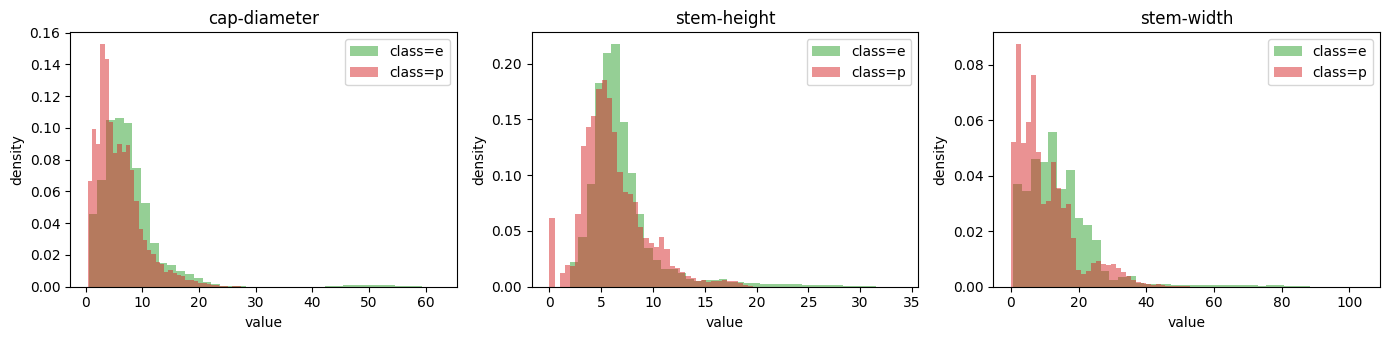

In [7]:
# ==================== EDA: Numeric Feature Distributions ====================
num_cols = ['cap-diameter', 'stem-height', 'stem-width']

print("Overall distribution:")
print(raw[num_cols].describe().round(2))
print(f"\nMissing counts: {raw[num_cols].isnull().sum().to_dict()}")
print(f"Skewness:       {raw[num_cols].skew().round(2).to_dict()}")
print("\nClass-conditional median:")
print(raw.groupby('class')[num_cols].median().round(2))

# Overlaid histograms per class
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, num_cols):
    for cls, color in [('e', 'tab:green'), ('p', 'tab:red')]:
        ax.hist(raw.loc[raw['class'] == cls, col].dropna(),
                bins=40, alpha=0.5, label=f"class={cls}", color=color, density=True)
    ax.set_title(col); ax.set_xlabel('value'); ax.set_ylabel('density')
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Preprocessing

**Fix**: the previous pipeline applied `LabelEncoder` to every categorical column. `LabelEncoder` maps unordered categories to arbitrary integers, which:

1. Misleads `LogisticRegression` and `MLP` — they treat the integers as real numbers on a line and interpolate between them.
2. Corrupts the Euclidean geometry used by D-optimal selection — the "distance" between `brown=0` and `white=2` is meaningless.

We now use `OneHotEncoder` for categoricals and `StandardScaler` for the three numeric columns. Encoding is fit on the full dataset once, which is safe because the transformer does not use labels.

In [8]:
# Step 1: treat NaN as an explicit 'missing' category
pool_data = pool_data.fillna('missing')

# Step 2: binary target (0 = edible, 1 = poisonous)
y = pool_data['class'].map({'e': 0, 'p': 1}).values
X_raw = pool_data.drop(columns=['class'])

# Step 3: identify numeric vs categorical columns
numeric_cols = ['cap-diameter', 'stem-height', 'stem-width']
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]

# Step 4: fit the transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
    ]
)
X = preprocessor.fit_transform(X_raw)
print(f"Feature matrix after encoding: {X.shape}")

Feature matrix after encoding: (61069, 128)


## 3. Train+Pool / Test Split

**Fix**: previously model quality was measured via 5-fold CV *on the labeled set itself*. This is biased two ways:

1. **Selection bias** — the labeled set is not i.i.d. with the deployment distribution. Query strategies deliberately oversample hard / uncertain regions, which makes CV underestimate true test performance. (Same i.i.d. violation we handle in ALICE via importance weighting.)
2. **High variance** — 5-fold CV on a 200-sample set gives ~40 points per fold; any accuracy estimate has very wide error bars.

Solution: carve out a fixed 20% test set up front. The test set **never enters the AL loop**.

In [9]:
X_trainpool, X_test, y_trainpool, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Train+Pool: {X_trainpool.shape[0]:,} samples | Test: {X_test.shape[0]:,} samples")
print(f"Test class balance: edible={int(np.sum(y_test==0))}, poisonous={int(np.sum(y_test==1))}")

Train+Pool: 48,855 samples | Test: 12,214 samples
Test class balance: edible=5436, poisonous=6778


## 4. Initialization Strategies

Two strategies, **both class-stratified** for a fair comparison.

- **Random stratified**: uniformly sample within each class.
- **D-optimal (stratified)**: greedily maximize $\log|X^\top X + \lambda I|$ within each class, then merge. The ridge term $\lambda I$ keeps the determinant well-defined when the number of selected points is small relative to the feature dimension (which grows large after one-hot encoding).

**Fix**: previously random init was stratified but D-opt was not, so any performance gap could be an artifact of class balance rather than of the selection strategy itself.

In [10]:
def _d_optimal_greedy(X, n_select, n_candidates, ridge, rng):
    """Core greedy D-optimal routine operating on a given feature matrix."""
    n_samples, n_features = X.shape
    selected = []
    remaining = set(range(n_samples))

    # Seed with the point furthest from the origin
    first_idx = int(np.argmax(np.linalg.norm(X, axis=1)))
    selected.append(first_idx)
    remaining.remove(first_idx)

    reg = ridge * np.eye(n_features)

    for _ in range(n_select - 1):
        X_sel = X[selected]
        base = X_sel.T @ X_sel + reg

        # Subsample candidates for tractability
        cand = list(remaining)
        if len(cand) > n_candidates:
            cand = rng.choice(cand, n_candidates, replace=False).tolist()

        best_idx, best_logdet = None, -np.inf
        for idx in cand:
            x = X[idx]
            _, ld = np.linalg.slogdet(base + np.outer(x, x))
            if ld > best_logdet:
                best_logdet, best_idx = ld, idx

        selected.append(best_idx)
        remaining.remove(best_idx)

    return np.array(selected)


def random_stratified_init(X_pool, y_pool, n_init=200, random_state=None):
    """Random initialization preserving class proportions."""
    rng = np.random.RandomState(random_state)
    classes, counts = np.unique(y_pool, return_counts=True)
    selected = []
    for c, cnt in zip(classes, counts):
        class_idx = np.where(y_pool == c)[0]
        n_c = int(round(n_init * cnt / len(y_pool)))
        selected.extend(rng.choice(class_idx, size=n_c, replace=False).tolist())
    return np.array(selected[:n_init])


def d_optimal_init(X_pool, y_pool, n_init=200, n_candidates=1000,
                   ridge=1e-3, stratify=True, random_state=None):
    """
    Class-stratified D-optimal initialization.

    Allocates n_init proportionally to class frequencies, then runs greedy
    D-opt within each class and merges the selections.
    """
    rng = np.random.RandomState(random_state)

    if not stratify:
        return _d_optimal_greedy(X_pool, n_init, n_candidates, ridge, rng)

    classes, counts = np.unique(y_pool, return_counts=True)
    all_selected = []
    for c, cnt in zip(classes, counts):
        class_idx = np.where(y_pool == c)[0]     # global indices
        n_c = int(round(n_init * cnt / len(y_pool)))
        local = _d_optimal_greedy(X_pool[class_idx], n_c, n_candidates, ridge, rng)
        all_selected.extend(class_idx[local].tolist())
    return np.array(all_selected[:n_init])

## 5. Query Strategies

Each strategy has the signature:

```python
strategy(X_labeled, y_labeled, X_unlabeled, model, batch_size, **kwargs) -> np.ndarray
```

and returns indices into `X_unlabeled` to query next. Only the random baseline is implemented below; the others are placeholders with detailed specifications — we'll fill them in together.

In [11]:
def random_query(X_labeled, y_labeled, X_unlabeled, model, batch_size=50, random_state=None, **_):
    """
    Baseline: uniformly random sampling from the pool.
    Passive-learning equivalent; everything else should beat this to justify its complexity.
    """
    rng = np.random.RandomState(random_state)
    return rng.choice(len(X_unlabeled), batch_size, replace=False)

In [12]:
def uncertainty_query(X_labeled, y_labeled, X_unlabeled, model, batch_size=50, **_):
    """
    TODO: implement uncertainty sampling.

    For binary classification, least-confidence / margin / entropy are all equivalent
    (all pick points where P(y=1|x) is closest to 0.5), so we only need one of them.
    Entropy is the standard choice:

        H(x) = -p * log(p) - (1 - p) * log(1 - p),  where p = P(y=1 | x)

    Steps:
        1. p = model.predict_proba(X_unlabeled)[:, 1]
        2. entropy = -p*log(p) - (1-p)*log(1-p)   (clip p to avoid log(0))
        3. return the top-`batch_size` indices by entropy

    Expected behavior: concentrates queries near the decision boundary.
    Failure mode: in the first few rounds predict_proba may be miscalibrated
    (uncalibrated MLP or small-sample RF), making entropy noisy. Consider
    wrapping the learner with CalibratedClassifierCV(isotonic) if this matters.
    """
    raise NotImplementedError("TODO: implement uncertainty sampling")

In [13]:
def qbc_query(X_labeled, y_labeled, X_unlabeled, model, batch_size=50, **_):
    """
    TODO: implement Query-By-Committee using the RandomForest's internal trees.

    RandomForestClassifier IS a committee (100 trees), so we get QBC for free
    without training extra models. Disagreement metric: vote entropy.

        For each x in X_unlabeled:
            tree_votes = [tree.predict([x])[0] for tree in model.estimators_]
            p_hat = mean(tree_votes)                       # fraction voting for class 1
            vote_entropy(x) = -p_hat*log(p_hat) - (1 - p_hat)*log(1 - p_hat)

    Return the top-`batch_size` indices by vote entropy.

    Prerequisite: `model` must be a *trained* RandomForestClassifier (the loop
    calls model.fit before each query, so this is satisfied).
    If we want QBC with LogReg or MLP, we would need BaggingClassifier or manual
    bootstrap copies trained on X_labeled.
    """
    raise NotImplementedError("TODO: implement QBC via RF's internal committee")

In [ ]:
def bald_query(X_labeled, y_labeled, X_unlabeled, model, batch_size=50, **_):
    """
    TODO: implement BALD (Bayesian Active Learning by Disagreement).

    BALD score = I(y ; w | x, D)
               = H(E_w[p(y | x, w)])  -  E_w[H(p(y | x, w))]
                 ^^^^^^^^^^^^^^^^^^^       ^^^^^^^^^^^^^^^^^^^
                 total predictive H         aleatoric (data noise)

        BALD = total - aleatoric = epistemic (model knowledge gap)

    Approximation: MC Dropout (Gal & Ghahramani, 2016).
    Do T stochastic forward passes with dropout ENABLED at inference time.

    sklearn's MLPClassifier does NOT support inference-time dropout, so this
    requires a PyTorch model. Skeleton:

        import torch
        import torch.nn as nn
        import torch.nn.functional as F

        class MCDropoutMLP(nn.Module):
            def __init__(self, d_in, d_hidden=128, p_drop=0.5):
                super().__init__()
                self.fc1 = nn.Linear(d_in, d_hidden)
                self.drop = nn.Dropout(p_drop)
                self.fc2 = nn.Linear(d_hidden, 2)

            def forward(self, x):
                return self.fc2(self.drop(F.relu(self.fc1(x))))

        # At inference, keep the model in .train() mode so dropout stays active.
        model.train()
        with torch.no_grad():
            probs = torch.stack([
                F.softmax(model(x_batch), dim=-1) for _ in range(T)
            ])                                              # shape: T x N x 2
        mean_p  = probs.mean(0)                              # N x 2
        total_H = -(mean_p * mean_p.clamp_min(1e-12).log()).sum(-1)
        mean_H  = -(probs * probs.clamp_min(1e-12).log()).sum(-1).mean(0)
        bald    = total_H - mean_H                           # N

    Return top-`batch_size` indices by BALD score.
    """
    raise NotImplementedError("TODO: BALD requires a PyTorch MC-Dropout MLP")

In [ ]:
def cost_weighted_uncertainty_query(
    X_labeled, y_labeled, X_unlabeled, model, batch_size=50, alpha=1.0, **_
):
    """
    TODO: cost-sensitive active learning for the mushroom setting.

    Motivation: false negatives (poisonous mushroom labeled edible) are far more
    costly than false positives in this application. Pure-uncertainty sampling
    treats both sides of the decision boundary symmetrically, which doesn't
    match the real-world risk.

    Proposed score:

        score(x) = entropy(x) * (1 + alpha * P(edible | x))

    Interpretation: among uncertain points, prioritize those the model *leans
    toward calling edible*, because misclassification in that direction is the
    dangerous case.

    alpha controls the asymmetry:
        alpha = 0       -> plain uncertainty sampling
        alpha -> inf    -> pure "safe-side-focused" sampling

    This is a minimal instance of Proactive / Cost-Sensitive AL from lecture.
    Evaluate using `poisonous_recall` in addition to accuracy to see whether
    the asymmetric query pays off in the metric that matters.
    """
    raise NotImplementedError("TODO: cost-weighted query for the mushroom task")

## 6. Base Learners

Factory returning fresh instances per call. The AL loop retrains from scratch each round, so we want a way to get a clean learner without carrying state across experiments.

In [14]:
def make_learners(random_state=RANDOM_STATE):
    """Return a dict of fresh learner instances."""
    return {
        'LogReg': LogisticRegression(max_iter=1000, random_state=random_state),
        'RandomForest': RandomForestClassifier(
            n_estimators=100, random_state=random_state, n_jobs=-1
        ),
        'MLP': MLPClassifier(
            hidden_layer_sizes=(128, 64), max_iter=500, random_state=random_state
        ),
    }

## 7. Evaluation Metrics

**Poisonous recall** is the safety-critical metric for this application: it measures the fraction of actually-poisonous mushrooms the model correctly flags. Missing a poisonous mushroom is a serious harm; misclassifying an edible one is only an inconvenience.

In [15]:
def evaluate(model, X_test, y_test):
    """Battery of test-set metrics. Call after model.fit(X_labeled, y_labeled)."""
    y_pred = model.predict(X_test)
    return {
        'accuracy':          accuracy_score(y_test, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
        'poisonous_recall':  recall_score(y_test, y_pred, pos_label=1),
        'poisonous_f1':      f1_score(y_test, y_pred, pos_label=1),
    }

In [19]:
# ==================== EDA: Fully-Supervised Accuracy Ceiling ====================
rf_full = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_full.fit(X_trainpool, y_trainpool)

ceiling = evaluate(rf_full, X_test, y_test)
print("Upper bound (RF trained on full train+pool, evaluated on held-out test):")
for k, v in ceiling.items():
    print(f"  {k:20s} {v:.4f}")

# Top-15 most important one-hot features
feat_names = preprocessor.get_feature_names_out()
importance = pd.Series(rf_full.feature_importances_, index=feat_names).sort_values(ascending=False)
print("\nTop 15 features by RF importance:")
print(importance.head(15).round(4).to_string())

Upper bound (RF trained on full train+pool, evaluated on held-out test):
  accuracy             1.0000
  balanced_accuracy    1.0000
  poisonous_recall     1.0000
  poisonous_f1         1.0000

Top 15 features by RF importance:
num__stem-width                 0.0782
num__stem-height                0.0488
num__cap-diameter               0.0473
cat__stem-color_w               0.0344
cat__gill-spacing_d             0.0225
cat__gill-spacing_c             0.0218
cat__gill-attachment_p          0.0201
cat__stem-surface_missing       0.0190
cat__gill-spacing_missing       0.0178
cat__gill-color_w               0.0177
cat__gill-attachment_d          0.0153
cat__does-bruise-or-bleed_t     0.0144
cat__cap-surface_missing        0.0140
cat__gill-attachment_missing    0.0138
cat__stem-surface_s             0.0138


## 8. Active Learning Loop

Refactor vs. Milestone 1:

- Evaluates on held-out `X_test, y_test`, not CV on the labeled set.
- Tracks multiple metrics every round, not just accuracy.
- Explicit `stop_reason` flag replaces the confusing `while ... else`.
- Operates on numpy arrays end-to-end (avoids pandas index-drift bugs after `.drop()`).
- `max_labels` is a hard budget cap; `target_value` is an optional early-stop trigger.

In [16]:
def active_learning_loop(
    model,
    X_init, y_init,
    X_pool, y_pool,
    X_test, y_test,
    query_strategy,
    batch_size=50,
    max_labels=2000,
    target_metric='accuracy',
    target_value=None,
    random_state=None,
    verbose=False,
):
    """
    Run one active-learning trajectory.

    Parameters
    ----------
    model : sklearn estimator supporting predict and predict_proba.
    X_init, y_init : initial labeled set (already selected by an init strategy).
    X_pool, y_pool : unlabeled pool; y_pool acts as the simulated oracle.
    X_test, y_test : fixed held-out test set (never modified).
    query_strategy : callable matching the strategy signature.
    batch_size : queries per round.
    max_labels : hard cap on labeled-set size.
    target_metric, target_value : optional early-stop condition.

    Returns
    -------
    dict with:
        history        : DataFrame, one row per round, columns = metrics + n_labels
        stop_reason    : 'target_reached' | 'budget_reached' | 'pool_exhausted'
        final_n_labels : int
    """
    # Work in numpy to avoid pandas index bugs after drops
    X_labeled   = np.array(X_init, copy=True)
    y_labeled   = np.array(y_init, copy=True)
    X_unlabeled = np.array(X_pool, copy=True)
    y_unlabeled = np.array(y_pool, copy=True)

    history = []
    stop_reason = 'pool_exhausted'  # default; overwritten if we break earlier

    while True:
        # --- train and evaluate ---
        model.fit(X_labeled, y_labeled)
        metrics = evaluate(model, X_test, y_test)
        metrics['n_labels'] = len(y_labeled)
        history.append(metrics)

        if verbose:
            print(f"n={metrics['n_labels']:4d} | "
                  f"acc={metrics['accuracy']:.4f} | "
                  f"pois_recall={metrics['poisonous_recall']:.4f}")

        # --- stopping checks ---
        if target_value is not None and metrics[target_metric] >= target_value:
            stop_reason = 'target_reached'
            break
        if len(X_labeled) >= max_labels:
            stop_reason = 'budget_reached'
            break
        if len(X_unlabeled) < batch_size:
            stop_reason = 'pool_exhausted'
            break

        # --- query next batch ---
        q_idx = query_strategy(
            X_labeled, y_labeled, X_unlabeled, model,
            batch_size=batch_size, random_state=random_state,
        )

        # --- move points: pool -> labeled ---
        X_labeled = np.vstack([X_labeled, X_unlabeled[q_idx]])
        y_labeled = np.concatenate([y_labeled, y_unlabeled[q_idx]])

        mask = np.ones(len(X_unlabeled), dtype=bool)
        mask[q_idx] = False
        X_unlabeled = X_unlabeled[mask]
        y_unlabeled = y_unlabeled[mask]

    return {
        'history':        pd.DataFrame(history),
        'stop_reason':    stop_reason,
        'final_n_labels': len(y_labeled),
    }

## 9. Build Initial Sets

In [17]:
N_INIT = 200

# --- random stratified init ---
rand_idx = random_stratified_init(
    X_trainpool, y_trainpool, n_init=N_INIT, random_state=RANDOM_STATE,
)
X_init_random = X_trainpool[rand_idx]
y_init_random = y_trainpool[rand_idx]
mask = np.ones(len(X_trainpool), dtype=bool); mask[rand_idx] = False
X_pool_random = X_trainpool[mask]
y_pool_random = y_trainpool[mask]

# --- D-optimal stratified init ---
dopt_idx = d_optimal_init(
    X_trainpool, y_trainpool, n_init=N_INIT,
    stratify=True, random_state=RANDOM_STATE,
)
X_init_dopt = X_trainpool[dopt_idx]
y_init_dopt = y_trainpool[dopt_idx]
mask = np.ones(len(X_trainpool), dtype=bool); mask[dopt_idx] = False
X_pool_dopt = X_trainpool[mask]
y_pool_dopt = y_trainpool[mask]

print(f"Random init  : edible={int(np.sum(y_init_random==0))}, poisonous={int(np.sum(y_init_random==1))}")
print(f"D-opt init   : edible={int(np.sum(y_init_dopt==0))}, poisonous={int(np.sum(y_init_dopt==1))}")

Random init  : edible=89, poisonous=111
D-opt init   : edible=89, poisonous=111


## 10. Baseline Smoke Test

Run RF + random sampling end-to-end to confirm the refactored loop works. Expect accuracy to climb smoothly and poisonous recall to track it.

In [18]:
learners = make_learners()
result = active_learning_loop(
    model=learners['RandomForest'],
    X_init=X_init_random, y_init=y_init_random,
    X_pool=X_pool_random, y_pool=y_pool_random,
    X_test=X_test, y_test=y_test,
    query_strategy=random_query,
    batch_size=50,
    max_labels=2000,
    target_metric='accuracy',
    target_value=0.97,
    random_state=RANDOM_STATE,
    verbose=True,
)
print(f"\nStopped: {result['stop_reason']} at {result['final_n_labels']} labels")
print("\nLast 5 rounds:")
print(result['history'].tail().to_string(index=False))

n= 200 | acc=0.8421 | pois_recall=0.8882
n= 250 | acc=0.8552 | pois_recall=0.8908
n= 300 | acc=0.8688 | pois_recall=0.9463
n= 350 | acc=0.8752 | pois_recall=0.9575
n= 400 | acc=0.9126 | pois_recall=0.9717
n= 450 | acc=0.9096 | pois_recall=0.9793
n= 500 | acc=0.9281 | pois_recall=0.9901
n= 550 | acc=0.9361 | pois_recall=0.9880
n= 600 | acc=0.9477 | pois_recall=0.9917
n= 650 | acc=0.9627 | pois_recall=0.9957
n= 700 | acc=0.9656 | pois_recall=0.9942
n= 750 | acc=0.9708 | pois_recall=0.9917

Stopped: target_reached at 750 labels

Last 5 rounds:
 accuracy  balanced_accuracy  poisonous_recall  poisonous_f1  n_labels
 0.936057           0.929639          0.988050      0.944903       550
 0.947683           0.942245          0.991738      0.954626       600
 0.962666           0.958586          0.995721      0.967321       650
 0.965613           0.962079          0.994246      0.969780       700
 0.970771           0.968183          0.991738      0.974132       750


## 11. Multi-Seed Experiment Runner (TODO)

Single-seed results can't distinguish strategy effects from noise. Wrap the loop to run across several seeds and aggregate.

In [ ]:
def run_experiment(
    init_fn, query_fn, learner_name,
    X_trainpool, y_trainpool, X_test, y_test,
    n_seeds=5, n_init=200, batch_size=50, max_labels=2000,
    target_metric='accuracy', target_value=None,
):
    """
    TODO: run the AL loop across `n_seeds` different random seeds.

    For each seed s in range(n_seeds):
        1. init_idx = init_fn(X_trainpool, y_trainpool, n_init=n_init, random_state=s)
        2. X_init, y_init = X_trainpool[init_idx], y_trainpool[init_idx]
        3. build the complementary pool via a boolean mask.
        4. model = make_learners(random_state=s)[learner_name]
        5. result = active_learning_loop(...).
        6. df = result['history'].copy(); df['seed'] = s; append to a list.

    Return a single DataFrame with columns:
        [seed, n_labels, accuracy, balanced_accuracy, poisonous_recall, poisonous_f1]

    so we can compute per-n_labels mean / std across seeds via groupby.
    """
    raise NotImplementedError("TODO: multi-seed wrapper")

## 12. Learning Curve Plotting (TODO)

Plot test metric vs. number of labels, one line per strategy, with a shaded band for ±1 std across seeds. This is the headline figure for the writeup.

In [ ]:
def plot_learning_curves(results_dict, metric='accuracy', ax=None, title=None):
    """
    TODO: plot learning curves with shaded std bands.

    Parameters
    ----------
    results_dict : {strategy_name: DataFrame from run_experiment}
    metric : one of {'accuracy', 'balanced_accuracy', 'poisonous_recall', 'poisonous_f1'}

    Implementation sketch:
        if ax is None:
            fig, ax = plt.subplots(figsize=(7, 4))
        for name, df in results_dict.items():
            agg = df.groupby('n_labels')[metric].agg(['mean', 'std']).reset_index()
            ax.plot(agg['n_labels'], agg['mean'], label=name)
            ax.fill_between(
                agg['n_labels'],
                agg['mean'] - agg['std'],
                agg['mean'] + agg['std'],
                alpha=0.2,
            )
        ax.set_xlabel('# labeled samples')
        ax.set_ylabel(metric)
        ax.set_title(title or f'Learning curves: {metric}')
        ax.legend()
        ax.grid(alpha=0.3)
    """
    raise NotImplementedError("TODO: plot_learning_curves")

## 13. Full Experiment Matrix (TODO)

The core output for milestone 2: sweep over

- **initialization**: {random_stratified, d_optimal}
- **query strategy**: {random, uncertainty, qbc, bald, cost_weighted}
- **classifier**: {LogReg, RandomForest, MLP}
- **seeds**: 5-10

Not every cell is meaningful — some constraints:

- `qbc` as implemented uses RF's internal committee, so it only pairs with `RandomForest`.
- `bald` needs an MC-Dropout model, so it pairs only with a PyTorch MLP (not the sklearn MLP).
- `uncertainty`, `random`, `cost_weighted` work with all three classifiers.

Build a list of valid `(init, strategy, classifier)` tuples rather than a full Cartesian grid.

In [ ]:
# TODO: experiment matrix runner.
# Expected output: a summary DataFrame with one row per (init, strategy, classifier) containing
#   - labels_to_target : smallest n_labels achieving target_value (or NaN if never reached)
#   - final_accuracy, final_poisonous_recall
#   - label_savings_pct : 100 * (1 - labels_to_target / labels_to_target_random_baseline)
#
# Plus a collection of learning-curve plots: one per classifier, showing all strategies on
# that classifier overlaid, with shaded std bands across seeds.

## 14. Connection to the Gemini Dual-Judge System (notes)

Observation from Milestone 1: Judge A (feature-classifier) and Judge B (direct vision) sometimes disagree. By QBC logic, disagreement cases are the highest-information samples. Instead of forcing a 60/40 weighted consensus (which marginalizes the disagreement), we can:

1. Log disagreement cases with the photo + both judges' outputs.
2. Have a human expert label them.
3. Feed those labels back as new training data for the RandomForest (and/or use them to prompt-tune Judge B).

This closes the loop between the deployed product and the AL research pipeline — the two milestones become two halves of the same system rather than independent deliverables.